In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
data = load_iris()
X = pd.DataFrame(data.data, columns=data.feature_names)

print("Shape:", X.shape)
display(X.head())

Shape: (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [3]:
X_scaled = StandardScaler().fit_transform(X)

In [4]:
k_values = range(2, 9)
inertia = []
silhouette = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_scaled, labels))

results = pd.DataFrame({'K': k_values, 'Inertia': inertia, 'Silhouette': silhouette})
display(results)

,K,Inertia,Silhouette
0,2,222.361705,0.581750
1,3,139.820496,0.459948
2,4,114.092547,0.386941
3,5,90.927514,0.345901
4,6,81.544391,0.317079
5,7,72.631144,0.320197
6,8,62.540606,0.338692


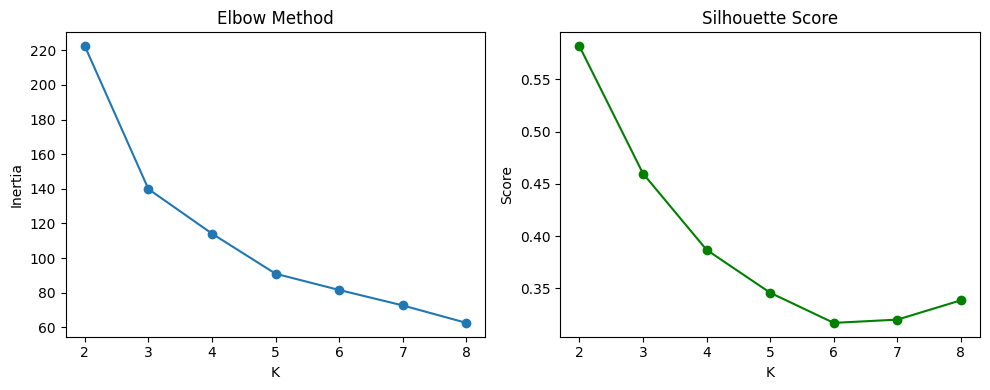

In [5]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(k_values, inertia, marker='o')
plt.title('Elbow Method')
plt.xlabel('K')
plt.ylabel('Inertia')

plt.subplot(1, 2, 2)
plt.plot(k_values, silhouette, marker='o', color='green')
plt.title('Silhouette Score')
plt.xlabel('K')
plt.ylabel('Score')

plt.tight_layout()
plt.show()

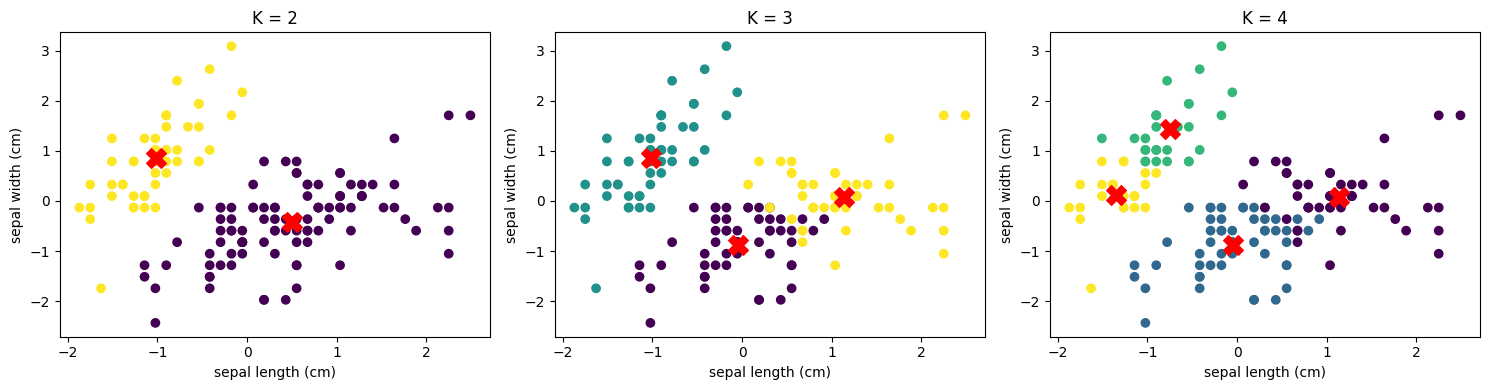

In [6]:
plt.figure(figsize=(15, 4))

for i, k in enumerate([2, 3, 4]):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)

    plt.subplot(1, 3, i + 1)
    plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels)
    plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c='red', marker='X', s=200)
    plt.title(f'K = {k}')
    plt.xlabel(data.feature_names[0])
    plt.ylabel(data.feature_names[1])

plt.tight_layout()
plt.show()